# Module 06, Part 2: Three families of pretrained Transformers

This notebook is the runnable companion to Part 2 of the Module 06 learning content.
It checks, with code:

1. The three mask patterns (full, causal, cross) are one line each, and the same attention
   function gives all three families.
2. A causal layer cannot see the future, and an unmasked layer can. We prove it by
   changing a token and watching which outputs move.
3. Why an unmasked model cannot be trained to generate: on a task whose next token is
   pure chance, the unmasked model scores almost perfectly by reading the answer, and the
   causal model scores at chance, which is the honest result.
4. A causal model trained on a rule can generate by predicting, appending and repeating.
5. In fine-tuning on prompt and answer pairs, scoring the prompt tokens changes the loss.

In [1]:
import math
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

INK, BODY, MUTED = "#14161B", "#4E5563", "#7C838C"
NAVY, GREEN, AMBER, KEY, RULE = "#1C3D6E", "#0E6B57", "#8A6A18", "#7A2E8A", "#D9DCE2"

plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": RULE, "axes.labelcolor": BODY, "xtick.color": BODY, "ytick.color": BODY,
    "axes.grid": True, "grid.color": RULE, "font.size": 10,
})

torch.manual_seed(0)
print("PyTorch version:", torch.__version__)

PyTorch version: 2.15.0+cpu


## 1. One attention function, three masks

True means "this query position may attend to this key position". Attention itself is
unchanged from Module 05; only the mask differs.

In [2]:
import math

import torch


def full_mask(n_queries, n_keys=None):
    """Encoder-style mask: every query sees every key."""
    return torch.ones(n_queries, n_keys or n_queries, dtype=torch.bool)


def causal_mask(length):
    """Decoder-style mask: query i sees keys 0..i, never the future."""
    return torch.tril(torch.ones(length, length, dtype=torch.bool))


def cross_mask(n_decoder, n_encoder):
    """Cross-attention: every decoder query sees every encoder key."""
    return torch.ones(n_decoder, n_encoder, dtype=torch.bool)


def attention(q, k, v, mask=None):
    """softmax(q k^T / sqrt(d)) v with an optional boolean mask. Returns (output, weights)."""
    scores = q @ k.transpose(-2, -1) / math.sqrt(q.shape[-1])
    if mask is not None:
        scores = scores.masked_fill(~mask, float("-inf"))
    weights = torch.softmax(scores, dim=-1)
    return weights @ v, weights


class SelfAttentionLayer(torch.nn.Module):
    """One single-head self-attention layer with a residual connection."""

    def __init__(self, d_model):
        super().__init__()
        self.q = torch.nn.Linear(d_model, d_model)
        self.k = torch.nn.Linear(d_model, d_model)
        self.v = torch.nn.Linear(d_model, d_model)
        self.o = torch.nn.Linear(d_model, d_model)

    def forward(self, x, mask=None):
        out, _ = attention(self.q(x), self.k(x), self.v(x), mask)
        return x + self.o(out)

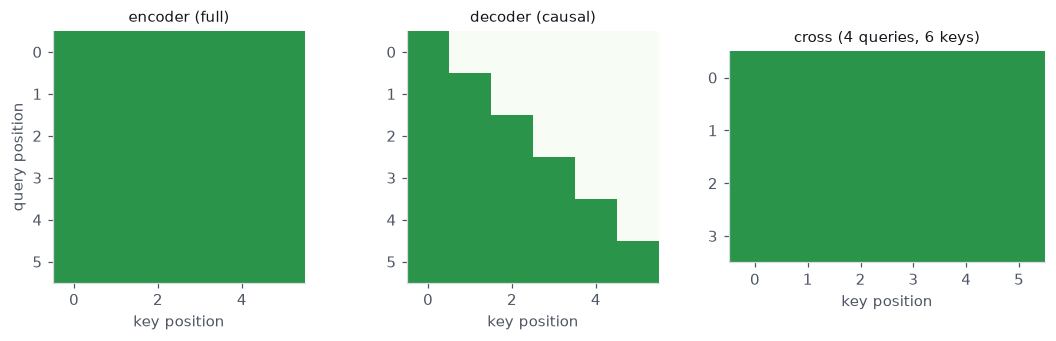

allowed pairs: {'encoder (full)': 36, 'decoder (causal)': 21, 'cross (4 queries, 6 keys)': 24}


In [3]:
T = 6
masks = {"encoder (full)": full_mask(T), "decoder (causal)": causal_mask(T), "cross (4 queries, 6 keys)": cross_mask(4, 6)}
fig, axes = plt.subplots(1, 3, figsize=(10, 3.1))
for ax, (name, m) in zip(axes, masks.items()):
    ax.imshow(m.numpy(), cmap="Greens", vmin=0, vmax=1.4)
    ax.set_title(name, fontsize=10, color=INK)
    ax.set_xlabel("key position"); ax.grid(False)
axes[0].set_ylabel("query position")
plt.tight_layout(); plt.show()
print("allowed pairs:", {k: int(v.sum()) for k, v in masks.items()})

## 2. A causal layer cannot see the future

Run one self-attention layer on a random sequence of 8 vectors, change the vector at
position 5, and measure how much the output moves at each position. With the causal
mask, positions 0 to 4 must not move at all. Without a mask they all move.

In [4]:
d_model = 16
layer = SelfAttentionLayer(d_model)
x = torch.randn(1, 8, d_model)
x2 = x.clone()
x2[:, 5] = torch.randn(d_model)

with torch.no_grad():
    for name, m in (("causal", causal_mask(8)), ("no mask", None)):
        change = (layer(x, m) - layer(x2, m)).norm(dim=-1)[0]
        print(f"{name:8s} change in output at positions 0..7:", [f"{c:.4f}" for c in change.tolist()])

causal   change in output at positions 0..7: ['0.0000', '0.0000', '0.0000', '0.0000', '0.0000', '5.2329', '0.1949', '0.3375']
no mask  change in output at positions 0..7: ['0.3059', '0.2180', '0.2700', '0.1921', '0.2247', '5.1833', '0.1655', '0.3375']


With the causal mask the change is exactly 0 up to position 4 and appears from position
5 on. That is the property generation needs: the prediction at position $t$ depends only
on positions up to $t$, so generating one token and appending it never changes the
earlier predictions. Without a mask the whole output moves, because every position reads
every other.

## 3. Why an unmasked model cannot be trained to generate

Build the simplest next-token task that has no rule at all: sequences of random tokens
from a vocabulary of 8. Predicting the next token is then pure chance, so the best any
honest model can do is $1/8 = 0.125$. We train the same small model twice, once with the
causal mask and once without.

In [5]:
V, L = 8, 16

class TinyLM(nn.Module):
    """Embedding, learned positions, one self-attention layer, a small feed-forward layer, a read-out per position."""
    def __init__(self, causal, d=64):
        super().__init__()
        self.embed, self.pos = nn.Embedding(V, d), nn.Embedding(L, d)
        self.attn, self.head, self.causal = SelfAttentionLayer(d), nn.Linear(d, V), causal
        self.ff = nn.Sequential(nn.Linear(d, 4 * d), nn.ReLU(), nn.Linear(4 * d, d))

    def forward(self, tokens):
        h = self.embed(tokens) + self.pos(torch.arange(tokens.shape[1]))
        h = self.attn(h, causal_mask(tokens.shape[1]) if self.causal else None)
        return self.head(h + self.ff(h))

def train_lm(model, make_batch, steps=800, lr=3e-3, seed=0):
    g = torch.Generator().manual_seed(seed)
    opt = torch.optim.Adam(model.parameters(), lr)
    for _ in range(steps):
        tokens = make_batch(64, g)
        loss = F.cross_entropy(model(tokens[:, :-1]).reshape(-1, V), tokens[:, 1:].reshape(-1))
        opt.zero_grad(); loss.backward(); opt.step()
    return model

def next_token_accuracy(model, make_batch, seed=999):
    g = torch.Generator().manual_seed(seed)
    tokens = make_batch(1000, g)
    with torch.no_grad():
        return (model(tokens[:, :-1]).argmax(-1) == tokens[:, 1:]).float().mean().item()

def random_batch(n, g):
    return torch.randint(0, V, (n, L), generator=g)

for causal in (True, False):
    torch.manual_seed(0)
    m = train_lm(TinyLM(causal), random_batch)
    print(f"{'causal mask' if causal else 'no mask':12s} next-token accuracy on random sequences: "
          f"{next_token_accuracy(m, random_batch):.3f}   (chance = {1 / V:.3f})")

causal mask  next-token accuracy on random sequences: 0.125   (chance = 0.125)
no mask      next-token accuracy on random sequences: 0.942   (chance = 0.125)


The causal model scores 0.126, which is chance (0.125). That is the correct answer, because
the next token really is unpredictable. The unmasked model scores 0.942, which looks
excellent and is meaningless: at position $t$ it can attend to position $t+1$, which
holds the answer, so it learns to copy it. Nothing it learned could be used to generate,
because at generation time the next token does not exist yet. A high score on a task is
only evidence of learning if the mask stops the model from reading the answer.

## 4. A causal model generates by predicting, appending and repeating

Now give the sequences a rule the model can learn: each token is the sum of the previous
two, modulo 8. The first two tokens are random, and everything after them is determined.
We train the causal model, then give it only the first two tokens and let it generate
the other 14 one at a time.

In [6]:
def rule_batch(n, g):
    t = torch.randint(0, V, (n, L), generator=g)
    for i in range(2, L):
        t[:, i] = (t[:, i - 1] + t[:, i - 2]) % V
    return t

torch.manual_seed(0)
lm = train_lm(TinyLM(causal=True), rule_batch, steps=3000)
print(f"next-token accuracy on rule sequences: {next_token_accuracy(lm, rule_batch):.3f}")

@torch.no_grad()
def generate(model, prompt, n_new):
    seq = prompt.clone()
    for _ in range(n_new):
        nxt = model(seq)[:, -1].argmax(-1, keepdim=True)     # predict, then append
        seq = torch.cat([seq, nxt], dim=1)
    return seq

g = torch.Generator().manual_seed(7)
truth = rule_batch(500, g)
out = generate(lm, truth[:, :2], L - 2)
print(f"sequences generated exactly right from a 2-token prompt: {(out == truth).all(dim=1).float().mean().item():.3f}")
print("one example, truth:    ", truth[0].tolist())
print("one example, generated:", out[0].tolist())

next-token accuracy on rule sequences: 0.943
sequences generated exactly right from a 2-token prompt: 1.000
one example, truth:     [7, 4, 3, 7, 2, 1, 3, 4, 7, 3, 2, 5, 7, 4, 3, 7]
one example, generated: [7, 4, 3, 7, 2, 1, 3, 4, 7, 3, 2, 5, 7, 4, 3, 7]


The causal model learns the rule: 0.942 next-token accuracy, which is the ceiling here
because the second token of each sequence is random and so cannot be predicted (14 of
the 15 predictions are determined). Given only two tokens it generates all 500 test
sequences exactly right, one token at a time, by predicting, appending and repeating.
One honest note: a single attention layer alone reached only 0.82 on this rule in our
tests, and adding the small feed-forward layer fixed it, so the layer is part of the
model and not decoration.

## 5. Score the answer tokens, not the prompt

When a decoder-only model is fine-tuned on a prompt followed by an answer, the loss is
usually computed on the answer tokens only. PyTorch's `ignore_index` does that: targets
set to -100 contribute nothing. Here a prompt of 6 tokens is followed by an answer of 2,
and the model's predictions are good on the answer and no better than chance on the
random prompt. Scoring everything dilutes the signal.

In [7]:
torch.manual_seed(0)
g = torch.Generator().manual_seed(3)
tokens = torch.randint(0, V, (256, 8), generator=g)                  # 6 random prompt tokens, then 2 answer tokens
tokens[:, 6] = tokens[:, 0]                                           # the answer is determined by the prompt
tokens[:, 7] = tokens[:, 1]

model = TinyLM(causal=True)
model.pos = nn.Embedding(8, 64)
inp, tgt = tokens[:, :-1], tokens[:, 1:]
opt = torch.optim.Adam(model.parameters(), 3e-3)
for _ in range(600):
    h = model.embed(inp) + model.pos(torch.arange(7))
    logits = model.head(model.attn(h, causal_mask(7)))   # attention only
    loss = F.cross_entropy(logits.reshape(-1, V), tgt.reshape(-1))
    opt.zero_grad(); loss.backward(); opt.step()

with torch.no_grad():
    h = model.embed(inp) + model.pos(torch.arange(7))
    logits = model.head(model.attn(h, causal_mask(7)))   # attention only
    answer_only = tgt.clone(); answer_only[:, :5] = -100              # score only the two answer positions
    all_tokens = F.cross_entropy(logits.reshape(-1, V), tgt.reshape(-1)).item()
    answers = F.cross_entropy(logits.reshape(-1, V), answer_only.reshape(-1), ignore_index=-100).item()
print(f"loss over all tokens (prompt and answer): {all_tokens:.3f}")
print(f"loss over answer tokens only:             {answers:.3f}")
print(f"loss of knowing nothing (log V):          {math.log(V):.3f}")

loss over all tokens (prompt and answer): 1.432
loss over answer tokens only:             0.196
loss of knowing nothing (log V):          2.079


Over all tokens the loss is 1.435. Over the two answer tokens it is 0.200, close to
zero, while the loss of knowing nothing is 2.079. The prompt tokens are random, so they
can never be predicted better than $\log V$, and scoring them adds a large constant
that the model cannot reduce. In real fine-tuning the prompt is not random, but the same
point holds: the loss curve over all tokens can look healthy while the model is barely
improving at answering. Check which tokens your training code is scoring.

## Try it

1. Build the three masks for 6 positions yourself and print them as 0 and 1. Then build
   the encoder-decoder pair: a full mask for the encoder, a causal mask for the decoder,
   and the cross mask between them.
2. In section 2, change the token at position 2 instead of 5. Which outputs move in each
   case?
3. In section 3, give the causal model one more attention layer. Does it help on random
   sequences? Why or why not?
4. In section 4, change the rule to $x_t = (x_{t-1} + 2\,x_{t-2}) \bmod 8$. Does the
   model still learn it, and how many training steps does it need?
5. For three tasks of your own (for example sentiment, translation and open-ended
   writing), say which family you would start from and which rung of the adaptation
   ladder.

## What this notebook showed

- The three families differ by the mask, and the mask is one line.
- A causal layer's outputs depend only on the past. That is what makes generation by
  predict, append and repeat well defined.
- A model that can see the answer scores almost perfectly and has learned nothing a
  generator could use. A high score on a masked-token or next-token task only means
  something if the mask matches the way the model will be used.
- Fine-tuning code must say which tokens are scored. The answer tokens carry the signal.